# ML-P-6

## NAME :- Anuj Thakre
## Class :- A-A2-20
## Roll no :- 20

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

In [7]:
df = pd.read_csv("seeds.csv")

In [8]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [9]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3,NaN,NaN
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3,NaN,NaN
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3,NaN,NaN
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3,NaN,NaN
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3,NaN,NaN


In [10]:
df.shape

(210, 10)

In [11]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)', 'Unnamed: 8', 'Unnamed: 9'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [13]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64
Unnamed: 8,object
Unnamed: 9,object


In [14]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
Perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
Compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
Length of kernel,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
Width of kernel,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
Asymmetry coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
Length of kernel groove,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500
"Class (1, 2, 3)",210.0,2.000000,0.818448,1.0000,1.00000,2.00000,3.000000,3.0000


In [16]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0
Unnamed: 8,208
Unnamed: 9,209


In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
X = df.drop("Class (1, 2, 3)",axis=1)
y_original = df["Class (1, 2, 3)"]

print("Input shape: ",X.shape)
print("Target shape : ",y_original.shape)

Input shape:  (210, 9)
Target shape :  (210,)


In [19]:
y = y_original - 1

print("Original classes : ",sorted(y_original.unique()))
print("New classes : ",sorted(y.unique()))



Original classes :  [np.int64(1), np.int64(2), np.int64(3)]
New classes :  [np.int64(0), np.int64(1), np.int64(2)]


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 168
Testing samples: 42


In [21]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [27]:
from sklearn.preprocessing import StandardScaler

# Drop any non-numeric columns like 'Unnamed: 8' and 'Unnamed: 9'
X_train_numeric = X_train.select_dtypes(include=[np.number])
X_test_numeric = X_test.select_dtypes(include=[np.number])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)

print("Successfully scaled X_train and X_test!")

Successfully scaled X_train and X_test!


In [30]:
# Drop non-numeric columns and scale safely
scaler.fit_transform(X_train.select_dtypes(include=[np.number]))

array([[-1.17682401, -1.1750583 , -1.02169157, ..., -1.35751947,
         1.43188942, -0.82441016],
       [-0.87298429, -1.06714618,  0.86676795, ..., -0.59897345,
        -0.3056117 , -1.63150367],
       [-0.12719589,  0.01968295, -0.66917913, ..., -0.40933695,
        -1.4432301 ,  0.1615857 ],
       ...,
       [ 1.83395138,  1.78481679,  0.74506722, ...,  1.5965365 ,
         0.97200114,  1.5846725 ],
       [-0.68998991, -0.62008172, -0.73632435, ..., -0.64170844,
         1.63403093, -0.18605408],
       [-1.25968938, -1.21359834, -1.50010131, ..., -1.47236974,
        -0.10870363, -0.64957378]])

In [31]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model.compile(optimizer = Adam(learning_rate=0.001), loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [34]:
loss = "sparse_categorical_crossentropy"

In [37]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [39]:
history = model.fit(
    X_train_scaled, y_train,
    # validation_data=(X_test_scaled, y_test),
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.3433 - loss: 0.9792 - val_accuracy: 0.4118 - val_loss: 0.9401
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4254 - loss: 0.9260 - val_accuracy: 0.4118 - val_loss: 0.9041
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4851 - loss: 0.8872 - val_accuracy: 0.4118 - val_loss: 0.8771
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5672 - loss: 0.8542 - val_accuracy: 0.4412 - val_loss: 0.8550
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5970 - loss: 0.8277 - val_accuracy: 0.5588 - val_loss: 0.8357
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6343 - loss: 0.8047 - val_accuracy: 0.6176 - val_loss: 0.8195
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6791 - loss: 0.7829 - val_accuracy: 0.6471 - val_loss: 0.8030
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7015 - loss: 0.7601 - val_accuracy: 0.7059 - val_loss

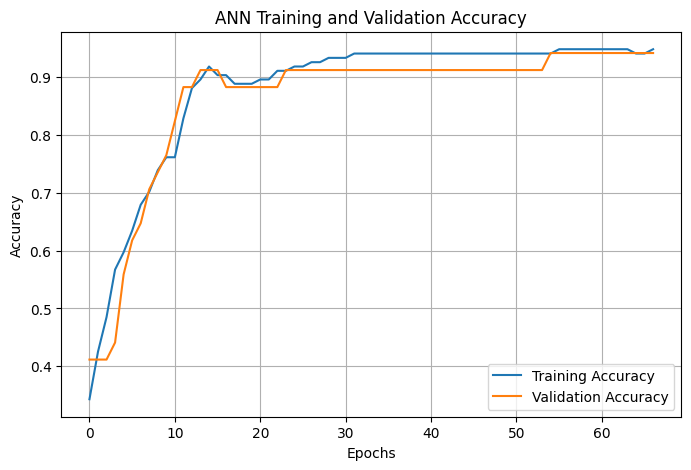

In [42]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

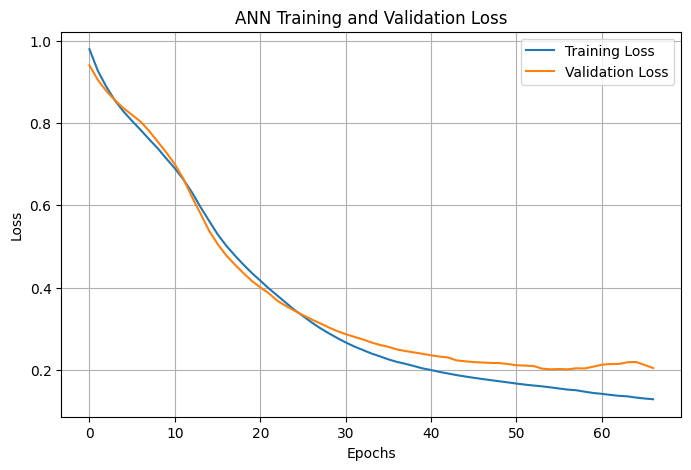

In [43]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
test_loss , test_accuracy = model.evaluate(X_test_scaled,y_test,verbose = 1)

print("Test loss : ", test_loss)
print("Test Accuracy : ",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.8571 - loss: 0.2889
Test loss :  0.28886762261390686
Test Accuracy :  0.8571428656578064


In [46]:
y_prob = model.predict(X_test_scaled,verbose = 1)

print(y_prob[:5])
y_pred = np.argmax(y_prob,axis=1)

print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[[9.6740240e-01 8.5617686e-03 2.4035832e-02]
 [4.9180523e-02 3.7412560e-03 9.4707823e-01]
 [1.4191966e-01 7.7039665e-01 8.7683693e-02]
 [3.8993591e-03 7.3795905e-05 9.9602687e-01]
 [1.3604022e-03 9.9796766e-01 6.7193585e-04]]
[0 2 1 2 1 2 1 1 1 1]


In [49]:
y_pred_original = y_pred + 1
y_test_original = y_test + 1

print("Predicited class :")
print(y_pred_original[:10])

Predicited class :
[1 3 2 3 2 3 2 2 2 2]


In [52]:
comparison = pd.DataFrame({'Actual Class': y_test_original, 'Predicted Class': y_pred_original})
comparison.head(5)

,Actual Class,Predicted Class
2,1,1
167,3,3
137,2,2
175,3,3
130,2,2


In [53]:
accuracy = accuracy_score(y_test_original, y_pred_original)
precision = precision_score(y_test_original, y_pred_original, average='weighted')
recall = recall_score(y_test_original, y_pred_original, average='weighted')
f1 = f1_score(y_test_original, y_pred_original, average='weighted')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8571428571428571
Precision: 0.8823529411764707
Recall: 0.8571428571428571
F1 Score: 0.8445747800586509


In [54]:
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [accuracy, precision, recall, f1]
})

print(metrics)

      Metric     Value
0   Accuracy  0.857143
1  Precision  0.882353
2     Recall  0.857143
3   F1 Score  0.844575


In [56]:
print(classification_report,(y_test_original,y_pred_original))

<function classification_report at 0x7ccd8f936de0> (2      1
167    3
137    2
175    3
130    2
141    3
114    2
51     1
84     2
110    2
23     1
182    3
129    2
131    2
171    3
29     1
168    3
14     1
190    3
43     1
52     1
181    3
122    2
60     1
94     2
21     1
61     1
65     1
162    3
20     1
154    3
98     2
1      1
146    3
152    3
109    2
95     2
93     2
161    3
37     1
198    3
117    2
Name: Class (1, 2, 3), dtype: int64, array([1, 3, 2, 3, 2, 3, 2, 2, 2, 2, 1, 3, 2, 2, 3, 1, 3, 1, 3, 2, 3, 3,
       2, 3, 2, 1, 3, 1, 3, 1, 3, 2, 1, 3, 3, 2, 2, 2, 3, 2, 3, 2]))


In [58]:
cm = confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]


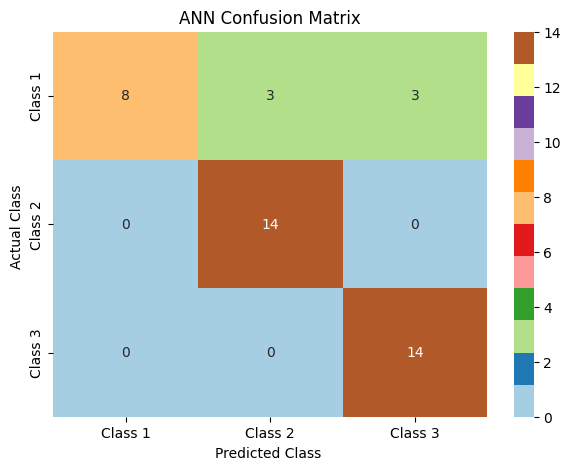

In [60]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Paired',
    xticklabels=["Class 1", "Class 2", "Class 3"],
    yticklabels=["Class 1", "Class 2", "Class 3"]
)

plt.xlabel("Predicted Class ")
plt.ylabel("Actual Class ")
plt.title("ANN Confusion Matrix")
plt.show()


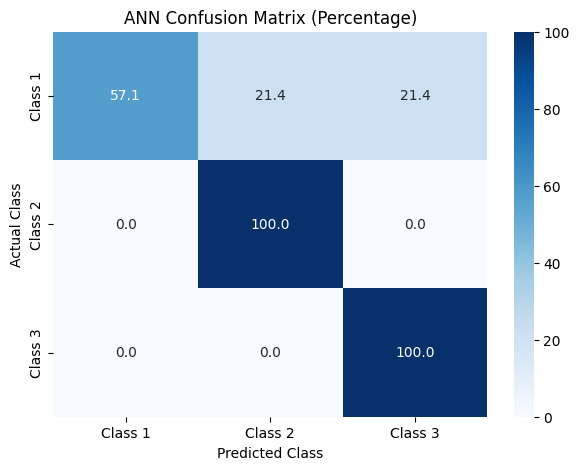

In [61]:
cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(7, 5))

sns.heatmap(cm_percentage, annot=True, fmt=".1f", cmap='Blues', xticklabels=["Class 1", "Class 2", "Class 3"], yticklabels=["Class 1", "Class 2", "Class 3"])

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN Confusion Matrix (Percentage)")
plt.show()

In [65]:
def predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove_length):
    new_seed_data = np.array([[area, perimeter, compactness, length, width, asymmetry, groove_length]])

    new_sample = pd.DataFrame(new_seed_data, columns=['Area', 'Perimeter', 'Compactness', 'Length', 'Width', 'Asymmetry', 'Groove Length'])
    new_sample_scaled = scaler.transform(new_sample)

    prediction = model.predict(new_sample_scaled)
    predicted_class = np.argmax(prediction, axis=1)


In [69]:

def predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove_length):
    new_seed_data = np.array([[area, perimeter, compactness, length, width, asymmetry, groove_length]])


    new_sample = pd.DataFrame(new_seed_data, columns=[
        'Area', 'Perimeter', 'Compactness',
        'Length of kernel', 'Width of kernel',
        'Asymmetry coefficient', 'Length of kernel groove'
    ])

    new_sample_scaled = scaler.transform(new_sample)
    prediction = model.predict(new_sample_scaled, verbose=0)
    predicted_class = np.argmax(prediction, axis=1)[0]


    print(f"\nPredicted Class: {predicted_class + 1}")

area = float(input("Enter the area of the seed: "))
perimeter = float(input("Enter the perimeter of the seed: "))
compactness = float(input("Enter the compactness of the seed: "))
length = float(input("Enter the length of the seed: "))
width = float(input("Enter the width of the seed: "))
asymmetry = float(input("Enter the asymmetry of the seed: "))
groove_length = float(input("Enter the groove length of the seed: "))

predict_new_seed(
    area,
    perimeter,
    compactness,
    length,
    width,
    asymmetry,
    groove_length
)

Enter the area of the seed: 15.26
Enter the perimeter of the seed: 14.84
Enter the compactness of the seed: 0.871
Enter the length of the seed: 5.763
Enter the width of the seed: 3.321
Enter the asymmetry of the seed: 2.2221
Enter the groove length of the seed: 5.21

Predicted Class: 1
